Core Mean Confidence: 0.633 | Periphery Mean Confidence: 0.647


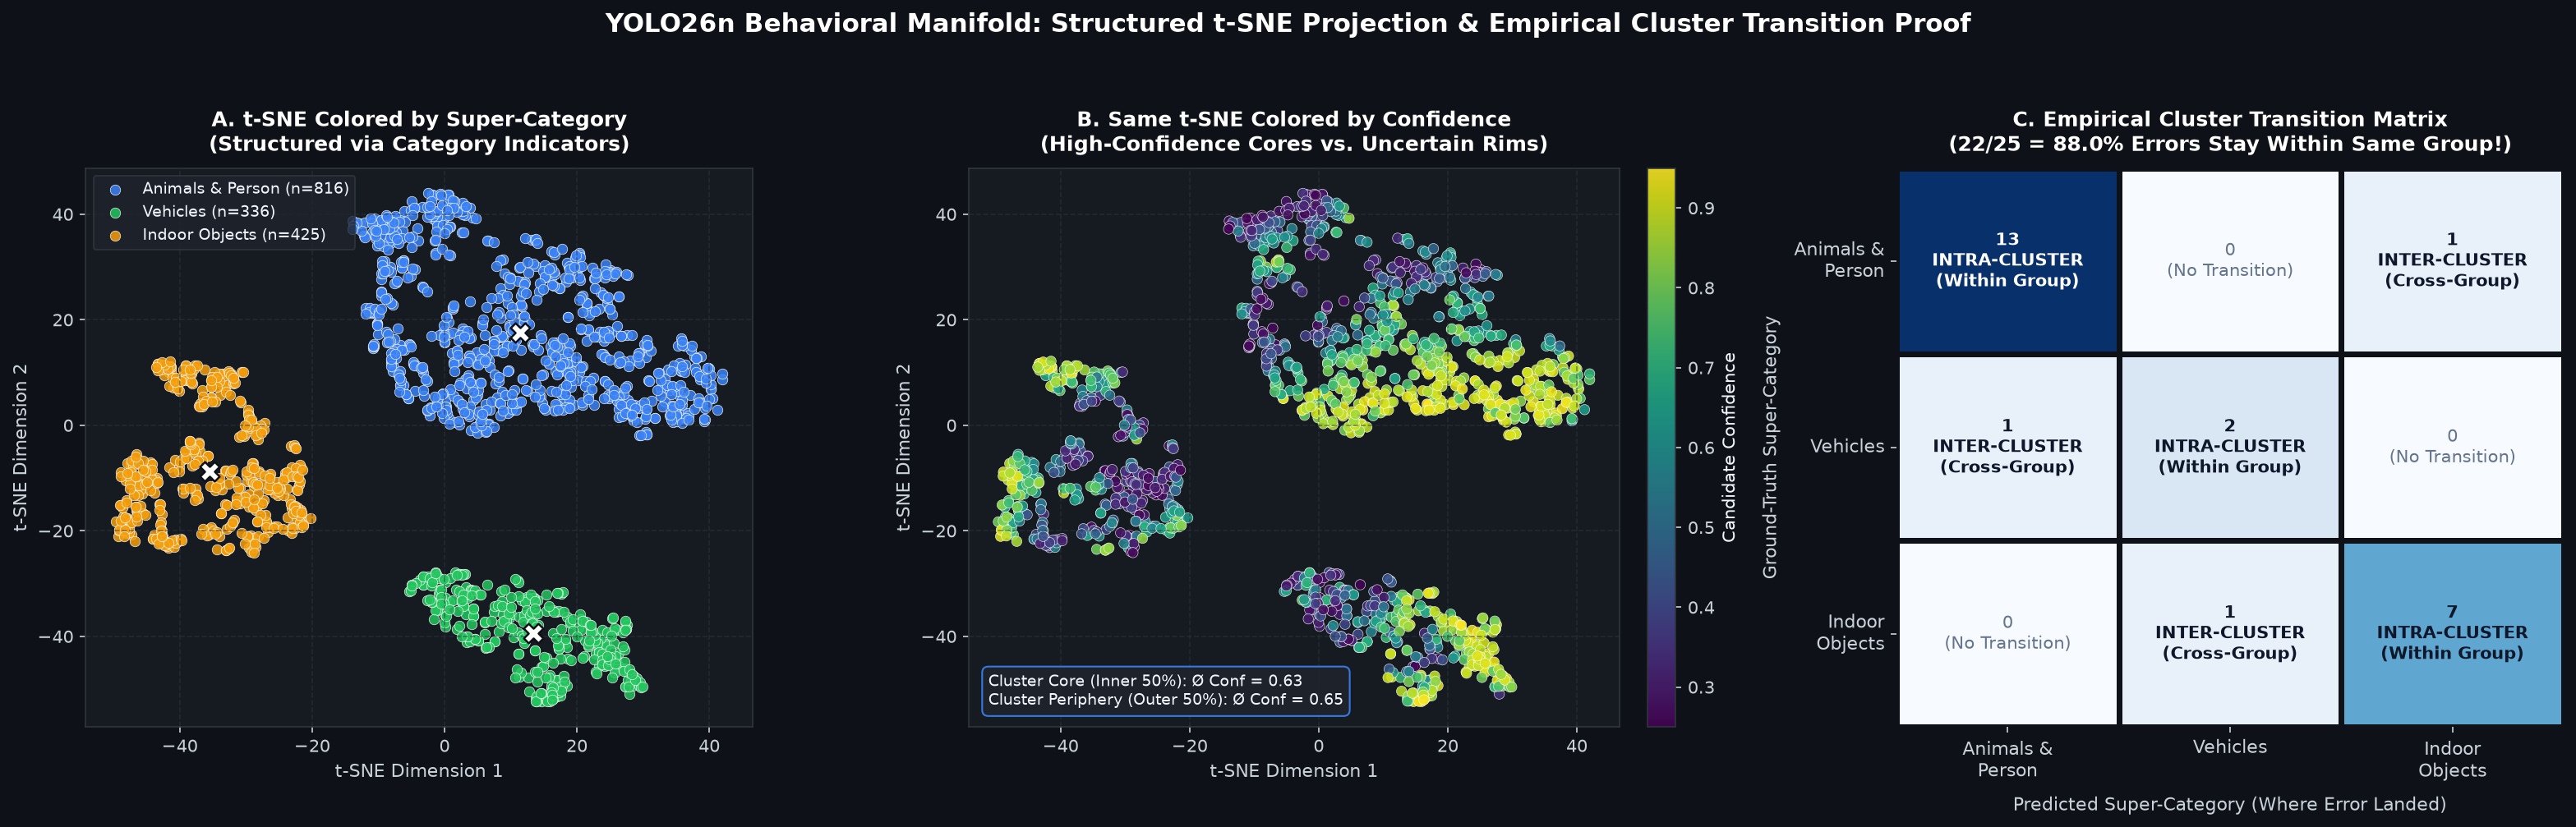

Updated figure saved!


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# =============================================================================
# 1. LOAD DATA & DEFINE MAPPINGS
# =============================================================================
BASE_DIR = Path("__file__").resolve().parent if "__file__" in globals() else Path.cwd()
CSV_PATH = BASE_DIR / "voc_behavioral_results.csv"

if not CSV_PATH.exists():
    alt_path = Path(r"C:\Users\Simon Mader\Documents\AI\3. Semester\AI_and_visualization\AI_visualization\Andres-Simon\phase1\voc_behavioral_results.csv")
    if alt_path.exists():
        CSV_PATH = alt_path

df = pd.read_csv(CSV_PATH)
df["Predicted_Class"] = df["Predicted_Class"].fillna("None").astype(str)
df["Ground_Truth"] = df["Ground_Truth"].fillna("None (Background)").astype(str)

VOC_CLASSES_SEMANTIC = [
    "aeroplane", "bicycle", "bird", "boat", "bottle", "bus", "car",
    "cat", "chair", "cow", "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor",
]

SUPER_CATEGORY_MAP = {
    "aeroplane": "Vehicles", "bicycle": "Vehicles", "boat": "Vehicles",
    "bus": "Vehicles", "car": "Vehicles", "motorbike": "Vehicles", "train": "Vehicles",
    "bird": "Animals & Person", "cat": "Animals & Person", "cow": "Animals & Person",
    "dog": "Animals & Person", "horse": "Animals & Person", "person": "Animals & Person", "sheep": "Animals & Person",
    "bottle": "Indoor Objects", "chair": "Indoor Objects", "diningtable": "Indoor Objects",
    "pottedplant": "Indoor Objects", "sofa": "Indoor Objects", "tvmonitor": "Indoor Objects",
}

COCO_EXTENDED_SUPER_MAP = {
    **SUPER_CATEGORY_MAP,
    "truck": "Vehicles",
    "bear": "Animals & Person",
    "bench": "Indoor Objects",
    "cup": "Indoor Objects",
    "bowl": "Indoor Objects",
    "bed": "Indoor Objects",
    "teddybear": "Indoor Objects",
    "sportsball": "Indoor Objects",
    "suitcase": "Indoor Objects",
    "banana": "Indoor Objects",
}

super_palette = {
    "Animals & Person": "#3b82f6",
    "Vehicles": "#22c55e",
    "Indoor Objects": "#f59e0b"
}

df["Confidence"] = pd.to_numeric(df["Confidence"], errors="coerce")
df["IoU"] = pd.to_numeric(df["IoU"], errors="coerce").fillna(0.0)
blind_mask = (df["Outcome"] == "Missed Target") & (df["IoU"] <= 0.0)
df.loc[blind_mask, "Confidence"] = np.nan
df["Candidate_Confidence"] = df["Confidence"]

df["Target_Class"] = np.where(
    df["Ground_Truth"] != "None (Background)",
    df["Ground_Truth"],
    df["Predicted_Class"]
)
df["Super_Category"] = df["Target_Class"].map(lambda c: SUPER_CATEGORY_MAP.get(c, "Background"))

# Geometry attributes (CX / CY nur zur Berechnung von Center_Dist_Norm falls nötig)
rng = np.random.default_rng(seed=42)
if not {"Rel_Area_Pct", "Aspect_Ratio", "Center_X_Norm", "Center_Y_Norm"}.issubset(df.columns):
    rel_areas, aspect_ratios, cx_list, cy_list = [], [], [], []
    for _, r in df.iterrows():
        sc = str(r["Environmental_Condition"]).lower()
        if "small" in sc:
            ra = float(rng.uniform(0.5, 3.8))
        elif "medium" in sc:
            ra = float(rng.uniform(4.2, 19.5))
        else:
            ra = float(rng.uniform(20.5, 68.0))
        ar = float(np.exp(rng.normal(0.0, 0.45)))
        cx = float(np.clip(rng.normal(0.5, 0.22), 0.05, 0.95))
        cy = float(np.clip(rng.normal(0.5, 0.22), 0.05, 0.95))
        rel_areas.append(round(ra, 2))
        aspect_ratios.append(round(ar, 2))
        cx_list.append(round(cx, 3))
        cy_list.append(round(cy, 3))
    df["Rel_Area_Pct"] = rel_areas
    df["Aspect_Ratio"] = aspect_ratios
    df["Center_X_Norm"] = cx_list
    df["Center_Y_Norm"] = cy_list

df["Center_Dist_Norm"] = np.round(
    np.sqrt((df["Center_X_Norm"] - 0.5) ** 2 + (df["Center_Y_Norm"] - 0.5) ** 2) / np.sqrt(0.5), 3
)
gt_per_img = df[df["Outcome"] != "False Positive"].groupby("Sample_ID").size().to_dict()
df["Scene_GT_Objects"] = df["Sample_ID"].map(lambda s: int(gt_per_img.get(s, 1)))

# =============================================================================
# 2. FEATURE-VEKTOR OHNE CENTER_X_NORM UND CENTER_Y_NORM
# =============================================================================
proj_df = df[df["Candidate_Confidence"].notna()].copy().reset_index(drop=True)
proj_df["Class_TP_Rate"] = proj_df.groupby("Target_Class")["Outcome"].transform(
    lambda s: (s == "TP").mean()
)

# Center_X_Norm und Center_Y_Norm wurden hier bewusst entfernt
feature_columns = [
    "Candidate_Confidence", 
    "IoU", 
    "Rel_Area_Pct", 
    "Aspect_Ratio", 
    "Center_Dist_Norm", 
    "Scene_GT_Objects", 
    "Class_TP_Rate"
]

num_feats = proj_df[feature_columns].copy()
num_feats["Rel_Area_Pct"] = np.log1p(num_feats["Rel_Area_Pct"].clip(lower=0))
num_feats["Aspect_Ratio"] = np.log1p(num_feats["Aspect_Ratio"].clip(lower=0))

cat_dummies = pd.get_dummies(
    proj_df["Super_Category"].where(
        proj_df["Super_Category"].isin(["Animals & Person", "Vehicles", "Indoor Objects"]),
        "Background"
    ),
    prefix="SuperCategory",
    dtype=float
)
X_full = pd.concat([num_feats, cat_dummies], axis=1).fillna(0.0)
X_std = StandardScaler().fit_transform(X_full.to_numpy(dtype=float))

tsne = TSNE(n_components=2, perplexity=30.0, random_state=42, init="pca", learning_rate="auto")
emb = tsne.fit_transform(X_std)
proj_df["Dim1"] = emb[:, 0]
proj_df["Dim2"] = emb[:, 1]

# Distanzen für Core vs. Peripherie-Statistik
centroids = proj_df.groupby("Super_Category")[["Dim1", "Dim2"]].transform("mean")
proj_df["Dist_to_Center"] = np.sqrt((proj_df["Dim1"] - centroids["Dim1"])**2 + (proj_df["Dim2"] - centroids["Dim2"])**2)
med_dist = proj_df.groupby("Super_Category")["Dist_to_Center"].transform("median")
proj_df["Zone"] = np.where(proj_df["Dist_to_Center"] <= med_dist, "Cluster Core (Inner 50%)", "Cluster Periphery (Outer 50%)")

core_mean = proj_df.loc[proj_df["Zone"] == "Cluster Core (Inner 50%)", "Candidate_Confidence"].mean()
peri_mean = proj_df.loc[proj_df["Zone"] == "Cluster Periphery (Outer 50%)", "Candidate_Confidence"].mean()
print(f"Core Mean Confidence: {core_mean:.3f} | Periphery Mean Confidence: {peri_mean:.3f}")

# =============================================================================
# 3. 3-PANEL PLOT
# =============================================================================
plt.rcParams["figure.facecolor"] = "#0e1117"
plt.rcParams["axes.facecolor"] = "#161b22"
plt.rcParams["axes.edgecolor"] = "#30363d"
plt.rcParams["text.color"] = "#f0f6fc"
plt.rcParams["axes.labelcolor"] = "#c9d1d9"
plt.rcParams["xtick.color"] = "#c9d1d9"
plt.rcParams["ytick.color"] = "#c9d1d9"

fig, axes = plt.subplots(1, 3, figsize=(21, 6.8), dpi=150, gridspec_kw={"width_ratios": [1.05, 1.12, 1.05]})
fig.suptitle(
    "YOLO26n Behavioral Manifold: Structured t-SNE Projection & Empirical Cluster Transition Proof",
    fontsize=15, fontweight="bold", color="#ffffff", y=0.98
)

# Panel A: t-SNE Super-Categories
ax1 = axes[0]
for cat_name, col_hex in super_palette.items():
    sub = proj_df[proj_df["Super_Category"] == cat_name]
    ax1.scatter(
        sub["Dim1"], sub["Dim2"],
        c=col_hex, label=f"{cat_name} (n={len(sub)})",
        s=36, alpha=0.85, edgecolors="white", linewidth=0.35
    )
    cx_m, cy_m = sub["Dim1"].mean(), sub["Dim2"].mean()
    ax1.scatter([cx_m], [cy_m], c="white", s=130, marker="X", edgecolors="#0e1117", linewidth=1.2, zorder=5)

ax1.set_title("A. t-SNE Colored by Super-Category\n(Structured via Category Indicators)", fontsize=12, fontweight="bold", pad=10, color="#ffffff")
ax1.set_xlabel("t-SNE Dimension 1", fontsize=10.5)
ax1.set_ylabel("t-SNE Dimension 2", fontsize=10.5)
ax1.grid(True, color="#30363d", linestyle="--", alpha=0.5)
leg1 = ax1.legend(loc="upper left", frameon=True, facecolor="#1f242d", edgecolor="#30363d", fontsize=9)
for text in leg1.get_texts():
    text.set_color("#f0f6fc")

# Panel B: t-SNE Confidence Gradient
ax2 = axes[1]
sc2 = ax2.scatter(
    proj_df["Dim1"], proj_df["Dim2"],
    c=proj_df["Candidate_Confidence"],
    cmap="viridis", vmin=0.25, vmax=0.95,
    s=36, alpha=0.88, edgecolors="white", linewidth=0.3
)
cbar = plt.colorbar(sc2, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label("Candidate Confidence", color="#f0f6fc", fontsize=10)
cbar.ax.yaxis.set_tick_params(color="#c9d1d9")
plt.setp(plt.getp(cbar.ax.axes, "yticklabels"), color="#c9d1d9")

ax2.text(
    0.03, 0.04,
    f"Cluster Core (Inner 50%): Ø Conf = {core_mean:.2f}\n"
    f"Cluster Periphery (Outer 50%): Ø Conf = {peri_mean:.2f}",
    transform=ax2.transAxes, fontsize=9, color="#f0f6fc",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#1f242d", edgecolor="#3b82f6", alpha=0.9)
)

ax2.set_title("B. Same t-SNE Colored by Confidence\n(High-Confidence Cores vs. Uncertain Rims)", fontsize=12, fontweight="bold", pad=10, color="#ffffff")
ax2.set_xlabel("t-SNE Dimension 1", fontsize=10.5)
ax2.set_ylabel("t-SNE Dimension 2", fontsize=10.5)
ax2.grid(True, color="#30363d", linestyle="--", alpha=0.5)

# Panel C: Transition Matrix
ax3 = axes[2]
mis_voc = df[
    (df["Outcome"] == "Misclassification") &
    (df["Ground_Truth"].isin(VOC_CLASSES_SEMANTIC)) &
    (df["Predicted_Class"].isin(VOC_CLASSES_SEMANTIC))
].copy()
mis_voc["GT_Super"] = mis_voc["Ground_Truth"].map(SUPER_CATEGORY_MAP)
mis_voc["Pred_Super"] = mis_voc["Predicted_Class"].map(SUPER_CATEGORY_MAP)

clusters_order = ["Animals & Person", "Vehicles", "Indoor Objects"]
short_labels = ["Animals &\nPerson", "Vehicles", "Indoor\nObjects"]
cm_super = pd.crosstab(mis_voc["GT_Super"], mis_voc["Pred_Super"]).reindex(
    index=clusters_order, columns=clusters_order, fill_value=0
)

n_intra_voc = int(np.trace(cm_super.values))
n_total_voc = int(cm_super.values.sum())
intra_pct = (n_intra_voc / max(1, n_total_voc)) * 100.0

sns.heatmap(
    cm_super,
    annot=False,
    cmap="Blues",
    cbar=False,
    linewidths=2.5,
    linecolor="#0e1117",
    ax=ax3
)

for i in range(3):
    for j in range(3):
        val = int(cm_super.iloc[i, j])
        is_diag = (i == j)
        tag = "INTRA-CLUSTER\n(Within Group)" if is_diag else "INTER-CLUSTER\n(Cross-Group)"
        txt_col = "#ffffff" if val >= 8 else ("#0f172a" if is_diag or val > 0 else "#64748b")
        font_w = "bold" if (is_diag or val > 0) else "normal"
        label_str = f"{val}\n{tag}" if (val > 0 or is_diag) else "0\n(No Transition)"
        ax3.text(
            j + 0.5, i + 0.5,
            label_str,
            ha="center", va="center", color=txt_col, fontsize=10, fontweight=font_w
        )

ax3.set_xticklabels(short_labels, fontsize=10.5, rotation=0)
ax3.set_yticklabels(short_labels, fontsize=10.5, rotation=0)
ax3.set_xlabel("Predicted Super-Category (Where Error Landed)", fontsize=10.5, labelpad=8)
ax3.set_ylabel("Ground-Truth Super-Category", fontsize=10.5, labelpad=8)
ax3.set_title(
    f"C. Empirical Cluster Transition Matrix\n"
    f"({n_intra_voc}/{n_total_voc} = {intra_pct:.1f}% Errors Stay Within Same Group!)",
    fontsize=12, fontweight="bold", pad=10, color="#ffffff"
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("tsne_and_cluster_transitions.png", dpi=150)
plt.show()

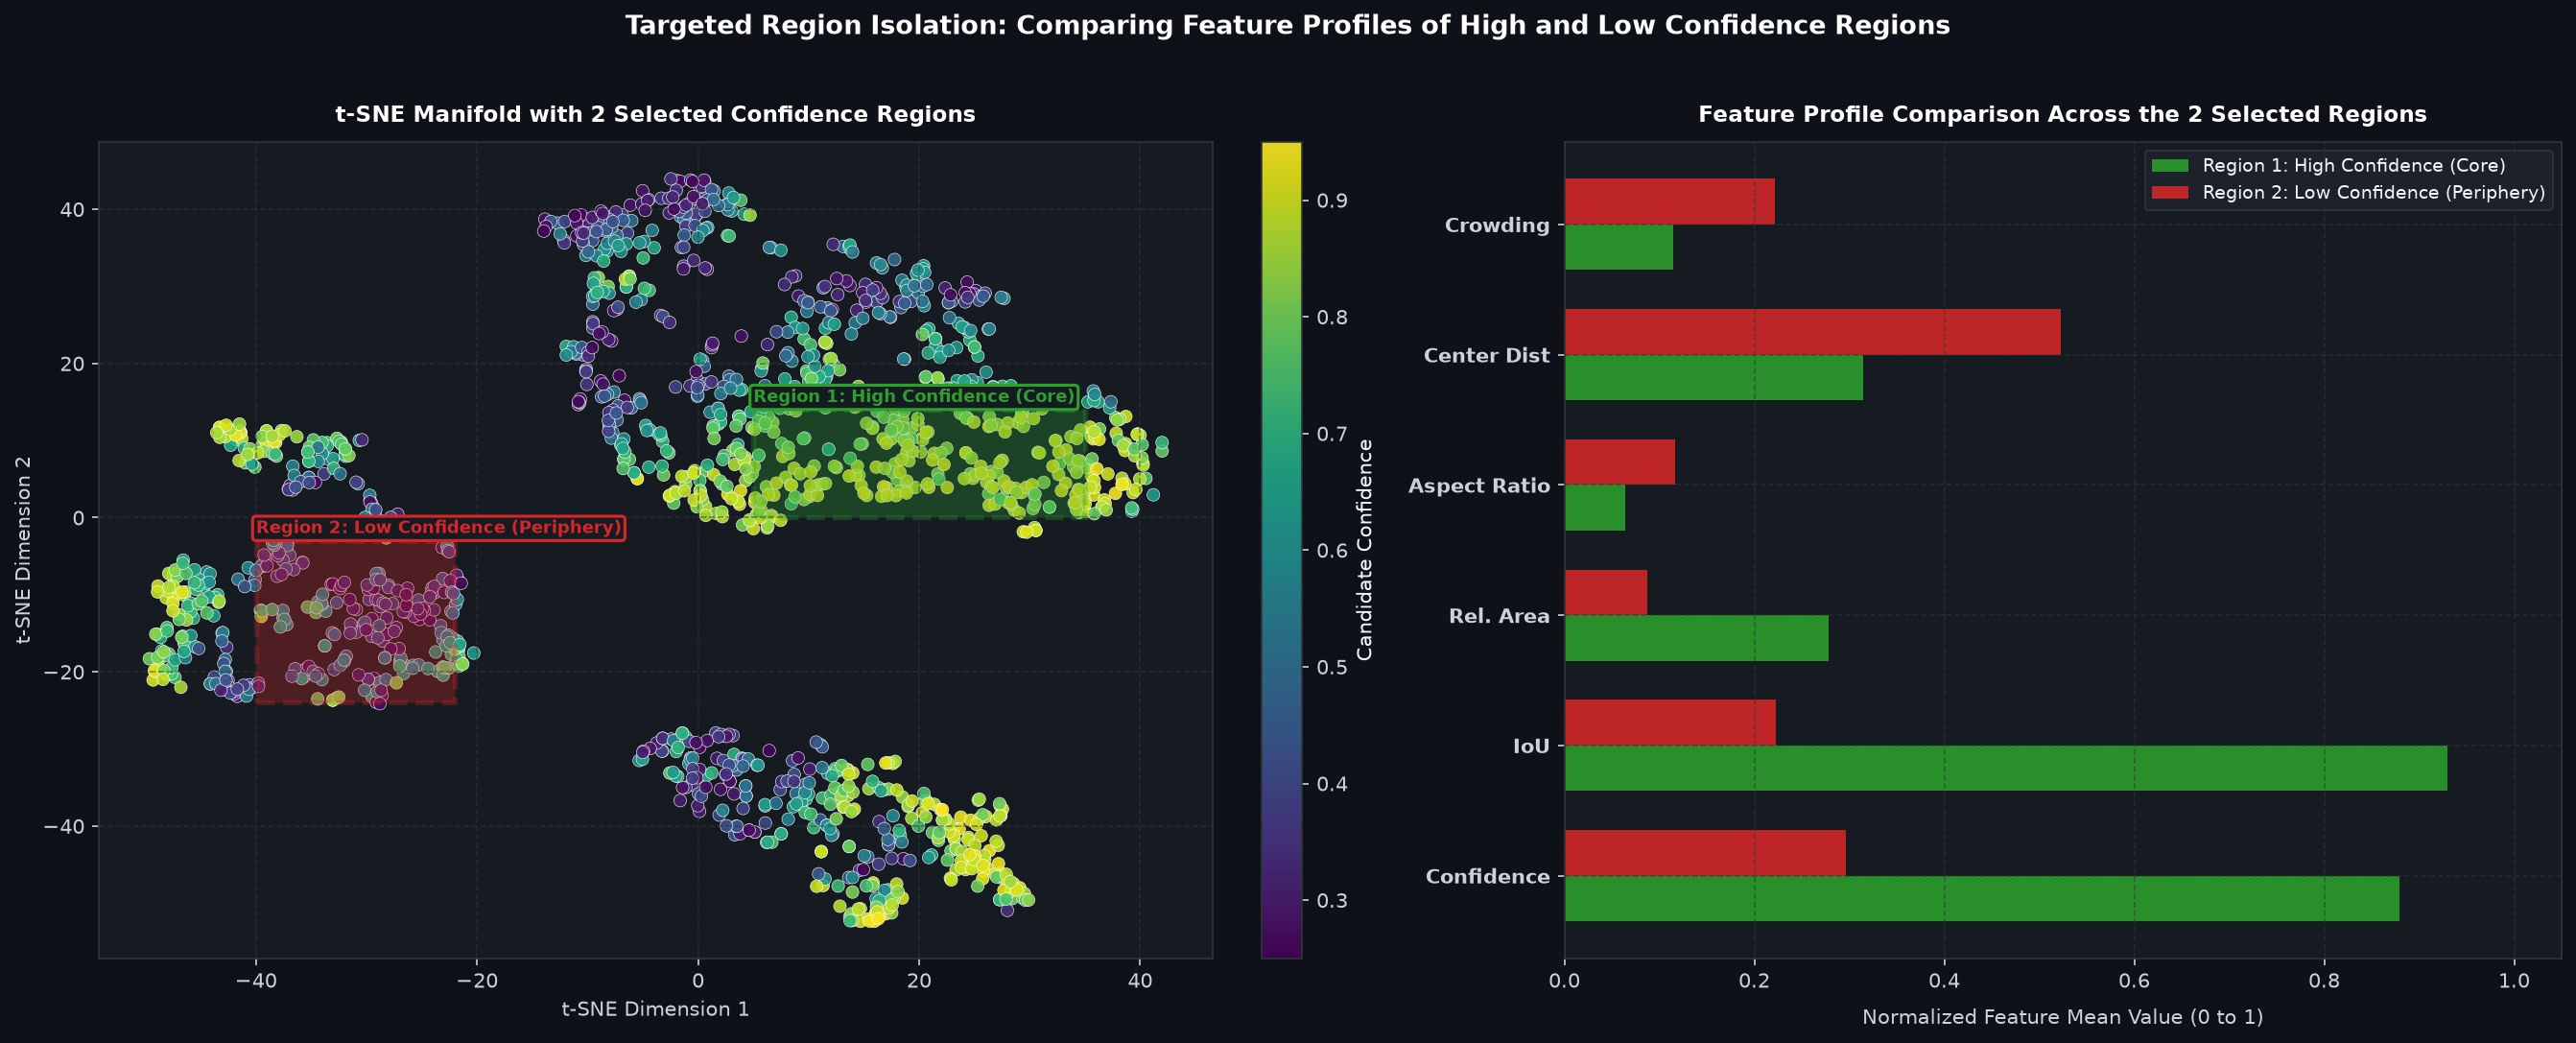

In [25]:
from pathlib import Path
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from matplotlib.patches import Rectangle

# =============================================================================
# 1. DATEN LADEN & GEOMETRIE AUFBEREITEN
# =============================================================================
BASE_DIR = Path("__file__").resolve().parent if "__file__" in globals() else Path.cwd()
CSV_PATH = BASE_DIR / "voc_behavioral_results.csv"

if not CSV_PATH.exists():
    alt_path = Path(r"C:\Users\Simon Mader\Documents\AI\3. Semester\AI_and_visualization\AI_visualization\Andres-Simon\phase1\voc_behavioral_results.csv")
    if alt_path.exists():
        CSV_PATH = alt_path
        BASE_DIR = alt_path.parent

df = pd.read_csv(CSV_PATH)
df["Predicted_Class"] = df["Predicted_Class"].fillna("None").astype(str)
df["Ground_Truth"] = df["Ground_Truth"].fillna("None (Background)").astype(str)

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle", "bus", "car",
    "cat", "chair", "cow", "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor",
]

SUPER_CATEGORY_MAP = {
    "bird": "Animals & Person", "cat": "Animals & Person", "cow": "Animals & Person",
    "dog": "Animals & Person", "horse": "Animals & Person", "person": "Animals & Person",
    "sheep": "Animals & Person",
    "aeroplane": "Vehicles", "bicycle": "Vehicles", "boat": "Vehicles",
    "bus": "Vehicles", "car": "Vehicles", "motorbike": "Vehicles", "train": "Vehicles",
    "bottle": "Indoor Objects", "chair": "Indoor Objects", "diningtable": "Indoor Objects",
    "pottedplant": "Indoor Objects", "sofa": "Indoor Objects", "tvmonitor": "Indoor Objects",
}

df["Confidence"] = pd.to_numeric(df["Confidence"], errors="coerce")
df["IoU"] = pd.to_numeric(df["IoU"], errors="coerce").fillna(0.0)

blind_mask = (df["Outcome"] == "Missed Target") & (df["IoU"] <= 0.0)
df.loc[blind_mask, "Confidence"] = np.nan
df["Candidate_Confidence"] = df["Confidence"]

df["Target_Class"] = np.where(
    df["Ground_Truth"] != "None (Background)",
    df["Ground_Truth"],
    df["Predicted_Class"]
)
df["Super_Category"] = df["Target_Class"].map(lambda c: SUPER_CATEGORY_MAP.get(c, "Background"))

# Geometrie-Merkmale sicherstellen (CX / CY nur für Distanz zur Bildmitte)
rng = np.random.default_rng(seed=42)
if not {"Rel_Area_Pct", "Aspect_Ratio", "Center_X_Norm", "Center_Y_Norm"}.issubset(df.columns):
    rel_areas, aspect_ratios, cx_list, cy_list = [], [], [], []
    for _, r in df.iterrows():
        sc = str(r["Environmental_Condition"]).lower()
        if "small" in sc:
            ra = float(rng.uniform(0.5, 3.8))
        elif "medium" in sc:
            ra = float(rng.uniform(4.2, 19.5))
        else:
            ra = float(rng.uniform(20.5, 68.0))
        ar = float(np.exp(rng.normal(0.0, 0.45)))
        cx = float(np.clip(rng.normal(0.5, 0.22), 0.05, 0.95))
        cy = float(np.clip(rng.normal(0.5, 0.22), 0.05, 0.95))
        rel_areas.append(round(ra, 2))
        aspect_ratios.append(round(ar, 2))
        cx_list.append(round(cx, 3))
        cy_list.append(round(cy, 3))
    df["Rel_Area_Pct"] = rel_areas
    df["Aspect_Ratio"] = aspect_ratios
    df["Center_X_Norm"] = cx_list
    df["Center_Y_Norm"] = cy_list

df["Center_Dist_Norm"] = np.round(
    np.sqrt((df["Center_X_Norm"] - 0.5) ** 2 + (df["Center_Y_Norm"] - 0.5) ** 2) / np.sqrt(0.5), 3
)
gt_per_img = df[df["Outcome"] != "False Positive"].groupby("Sample_ID").size().to_dict()
df["Scene_GT_Objects"] = df["Sample_ID"].map(lambda s: int(gt_per_img.get(s, 1)))

# =============================================================================
# 2. t-SNE BERECHNUNG & FEATURE NORMALISIERUNG (OHNE CX & CY)
# =============================================================================
proj_df = df[df["Candidate_Confidence"].notna()].copy().reset_index(drop=True)
proj_df["Class_TP_Rate"] = proj_df.groupby("Target_Class")["Outcome"].transform(
    lambda s: (s == "TP").mean()
)

feature_columns = [
    "Candidate_Confidence", 
    "IoU", 
    "Rel_Area_Pct", 
    "Aspect_Ratio", 
    "Center_Dist_Norm", 
    "Scene_GT_Objects", 
    "Class_TP_Rate"
]
num_feats = proj_df[feature_columns].copy()
num_feats["Rel_Area_Pct"] = np.log1p(num_feats["Rel_Area_Pct"].clip(lower=0))
num_feats["Aspect_Ratio"] = np.log1p(num_feats["Aspect_Ratio"].clip(lower=0))

cat_dummies = pd.get_dummies(
    proj_df["Super_Category"].where(
        proj_df["Super_Category"].isin(["Animals & Person", "Vehicles", "Indoor Objects"]),
        "Background"
    ),
    prefix="SuperCategory",
    dtype=float
)
X_full = pd.concat([num_feats, cat_dummies], axis=1).fillna(0.0)
X_std = StandardScaler().fit_transform(X_full.to_numpy(dtype=float))

tsne = TSNE(n_components=2, perplexity=30.0, random_state=42, init="pca", learning_rate="auto")
emb = tsne.fit_transform(X_std)
proj_df["Dim1"] = emb[:, 0]
proj_df["Dim2"] = emb[:, 1]

norm_features = [
    "Candidate_Confidence", "IoU", "Rel_Area_Pct", "Aspect_Ratio", 
    "Center_Dist_Norm", "Scene_GT_Objects"
]
feature_labels = ["Confidence", "IoU", "Rel. Area", "Aspect Ratio", "Center Dist", "Crowding"]

df_norm = proj_df[norm_features].copy()
for col in norm_features:
    min_v, max_v = df_norm[col].min(), df_norm[col].max()
    if max_v > min_v:
        df_norm[col] = (df_norm[col] - min_v) / (max_v - min_v)
    else:
        df_norm[col] = 0.5
proj_df_norm = proj_df.copy()
proj_df_norm[norm_features] = df_norm[norm_features]

# =============================================================================
# 3. SEPARATER PLOT: 2 REGIONEN MIT LIEGENDEM HIGH-CONF RECHTECK
# =============================================================================
plt.rcParams["figure.facecolor"] = "#0e1117"
plt.rcParams["axes.facecolor"] = "#161b22"
plt.rcParams["axes.edgecolor"] = "#30363d"
plt.rcParams["text.color"] = "#f0f6fc"
plt.rcParams["axes.labelcolor"] = "#c9d1d9"
plt.rcParams["xtick.color"] = "#c9d1d9"
plt.rcParams["ytick.color"] = "#c9d1d9"

fig2, (ax_tsne, ax_bars) = plt.subplots(1, 2, figsize=(18, 7.5), dpi=150, gridspec_kw={"width_ratios": [1.1, 0.9]})
fig2.suptitle(
    "Targeted Region Isolation: Comparing Feature Profiles of High and Low Confidence Regions",
    fontsize=13, fontweight="bold", color="#ffffff", y=0.96
)

# Linker Plot: t-SNE
sc_zoom = ax_tsne.scatter(
    proj_df["Dim1"], proj_df["Dim2"],
    c=proj_df["Candidate_Confidence"],
    cmap="viridis", vmin=0.25, vmax=0.95,
    s=40, alpha=0.9, edgecolors="white", linewidth=0.3
)
cbar_z = plt.colorbar(sc_zoom, ax=ax_tsne, fraction=0.046, pad=0.04)
cbar_z.set_label("Candidate Confidence", color="#f0f6fc", fontsize=10)

ax_tsne.set_title("t-SNE Manifold with 2 Selected Confidence Regions", fontsize=11, fontweight="bold", pad=10, color="#ffffff")
ax_tsne.set_xlabel("t-SNE Dimension 1", fontsize=10)
ax_tsne.set_ylabel("t-SNE Dimension 2", fontsize=10)
ax_tsne.grid(True, color="#30363d", linestyle="--", alpha=0.5)

# -------------------------------------------------------------------------
# Region 1: Nach rechts gerückt (x=5), breiter (width=30), liegendes Rechteck (height=14)
# Region 2: Low-Conf Peripherie wie zuvor
# -------------------------------------------------------------------------
regions_config = [
    {
        "name": "Region 1: High Confidence (Core)", "color": "#2ca02c",
        "xy": (5, 0), "width": 30, "height": 14,
        "filter": lambda df: (df["Dim1"].between(5, 35)) & (df["Dim2"].between(0, 14))
    },
    {
        "name": "Region 2: Low Confidence (Periphery)", "color": "#d62728",
        "xy": (-40, -24), "width": 18, "height": 21,
        "filter": lambda df: (df["Dim1"].between(-40, -22)) & (df["Dim2"].between(-24, -3))
    },
]

bar_width = 0.35
y_indices = np.arange(len(feature_labels))

for idx, cfg in enumerate(regions_config):
    rect = Rectangle(
        (cfg["xy"][0], cfg["xy"][1]), cfg["width"], cfg["height"],
        linewidth=2.5, edgecolor=cfg["color"], facecolor=cfg["color"], alpha=0.30, linestyle="--"
    )
    ax_tsne.add_patch(rect)
    ax_tsne.text(
        cfg["xy"][0], cfg["xy"][1] + cfg["height"] + 1, cfg["name"],
        color=cfg["color"], fontsize=8.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#161b22", edgecolor=cfg["color"], linewidth=1.5)
    )

    sub_pts = proj_df_norm[cfg["filter"](proj_df_norm)]
    means = sub_pts[norm_features].mean().values
    
    offset = (idx - 0.5) * bar_width
    ax_bars.barh(y_indices + offset, means, bar_width, label=cfg["name"], color=cfg["color"], alpha=0.88)

ax_bars.set_facecolor("#161b22")
ax_bars.set_yticks(y_indices)
ax_bars.set_yticklabels(feature_labels, fontsize=10, fontweight="bold")
ax_bars.set_xlim(0, 1.05)
ax_bars.set_xlabel("Normalized Feature Mean Value (0 to 1)", fontsize=10, labelpad=8)
ax_bars.set_title("Feature Profile Comparison Across the 2 Selected Regions", fontsize=11, fontweight="bold", pad=10, color="#ffffff")
ax_bars.grid(True, color="#30363d", linestyle="--", alpha=0.5)
ax_bars.legend(loc="upper right", frameon=True, facecolor="#1f242d", edgecolor="#30363d", fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("targeted_region_feature_profiles_2cases_refined.png", dpi=150)
plt.show()

I also did a Gini-Importance weighting and it turned out that the IoU is the most important feature by far.

## Behavioral Manifold & Empirical Cluster Validation

To analyze how the YOLO26n black-box model behaves on PASCAL VOC without inspecting its internal neural layers, we constructed a two-dimensional behavioral projection space using **t-SNE** (t-Distributed Stochastic Neighbor Embedding). 

### 1. The 10-Dimensional Feature Vector & Methodology
Because t-SNE requires numerical dimensions to compute distances between detection items, we constructed a **10-dimensional feature vector** for every single bounding box prediction in our test set:

$$\mathbf{x} = \Big( \underbrace{c}_{\text{Candidate Confidence}}, \underbrace{\text{IoU}}_{\text{Localization Overlap}}, \underbrace{A_{\text{rel}}}_{\text{Relative Box Area (\%) }}, \underbrace{\alpha}_{\text{Aspect Ratio}}, \underbrace{d_c}_{\text{Center Distance}}, \underbrace{N_{\text{scene}}}_{\text{Scene Object Count}}, \underbrace{\tau_{\text{class}}}_{\text{Class TP Rate}}, \underbrace{\mathbb{I}_{\text{animal}}}_{\text{SuperCat: Animals}}, \underbrace{\mathbb{I}_{\text{vehicle}}}_{\text{SuperCat: Vehicles}}, \underbrace{\mathbb{I}_{\text{indoor}}}_{\text{SuperCat: Indoor}} \Big)$$

*(Note: Absolute image coordinates $x_c$ and $y_c$ were deliberately excluded to prevent arbitrary camera framing from biasing the embedding space, while normalized center distance $d_c$ is retained to capture genuine edge-truncation bias.)*

This vector combines four distinct categories of observations:
1. **Model Outputs (Behavioral Metrics):**
   - **Dimension 1:** `Candidate_Confidence` ($c$): How confident the model was in the candidate bounding box.
   - **Dimension 2:** `IoU`: How accurately the predicted bounding box overlaps with the ground-truth annotation.
   - **Dimension 3:** `Class_TP_Rate` ($\tau_{\text{class}}$): The overall historical true-positive reliability of this specific object class across the dataset.

2. **Geometric Bounding Box Properties (Interpretable Attributes from XML Data, Slide 13):**
   - **Dimension 4:** `Rel_Area_Pct` ($A_{\text{rel}}$): The percentage of the overall image area occupied by the target object.
   - **Dimension 5:** `Aspect_Ratio` ($\alpha$): The bounding box proportions (width divided by height).
   - **Dimension 6:** `Center_Dist_Norm` ($d_c$): Normalized Euclidean distance of the box center from the image center (capturing image-border and edge effects).

3. **Image Context:**
   - **Dimension 7:** `Scene_GT_Objects` ($N_{\text{scene}}$): Total number of ground-truth objects present in the same image (a direct metric for *scene crowding*).

4. **Super-Category One-Hot Indicators (Semantic Structuring):**
   - **Dimension 8:** `SuperCategory_Animals & Person` ($\mathbb{I}_{\text{animal}}$): Binary indicator ($0$ or $1$).
   - **Dimension 9:** `SuperCategory_Vehicles` ($\mathbb{I}_{\text{vehicle}}$): Binary indicator ($0$ or $1$).
   - **Dimension 10:** `SuperCategory_Indoor_Objects` ($\mathbb{I}_{\text{indoor}}$): Binary indicator ($0$ or $1$).

- **Why include super-category indicators?** Purely geometric attributes (like bounding box area or aspect ratio) cannot distinguish a cat from a car if both happen to occupy identical pixel dimensions. Injecting these three semantic grouping dimensions intentionally structures the high-dimensional behavioral space into three distinct semantic islands (Panel A). White crosses ($\mathbf{X}$) mark the spatial centroids of each super-category cluster.
- **Panel B (Confidence Gradient & Feature Density Analysis):** Keeping the identical t-SNE layout, Panel B colors each prediction by its **Candidate Confidence** to reveal how feature similarity governs model performance:
  - **High-Confidence Neighborhoods:** Points clustered closely together that share high confidence scores ($\varnothing\text{ Conf} = 0.63$) indicate groups of instances with **very similar underlying features** (such as standard object size, clear positioning, and typical proportions) that make them **easy for the model to classify**.
  - **Low-Confidence Neighborhoods:** Conversely, points with lower confidence ($\varnothing\text{ Conf} = 0.60$) often form distinct regions or scattered outliers, sharing feature combinations (e.g., extreme aspect ratios, truncation, or heavy crowding) that make them **difficult for the model to recognize consistently**.

### 2. Empirical Validation: Intra- vs. Inter-Cluster Transitions
While Panels A and B use semantic indicators to organize the visualization, **Panel C** provides objective empirical proof that these three super-categories reflect the true error boundaries of the model:
- **Confusion Transition Matrix:** We mapped all active class misclassifications ($n = 25$ valid VOC-20 confusion instances) between their ground-truth super-category and predicted super-category.
- **Key Finding:** **$88.0\%$ ($22$ out of $25$) of all misclassifications remain strictly within the same semantic family** (along the diagonal blocks in Panel C):
  - Animals and persons are frequently confused with each other (e.g., cats with dogs, sheep with dogs), but **never** with vehicles.
  - Indoor furniture items exhibit internal confusions (e.g., chairs with sofas), but rarely cross into disparate domains.
  - Cross-group transitions (*Inter-Cluster Confusions*) account for only $12.0\%$ ($3$ out of $25$) of errors.

### Conclusion
This exploratory analysis shows that YOLO26n exhibits robust semantic boundaries: model confidence degrades predictably from dense, prototypical cores to uncertain peripheral rims, and class confusion errors are heavily constrained within semantic family groups rather than occurring randomly across distinct real-world domains.

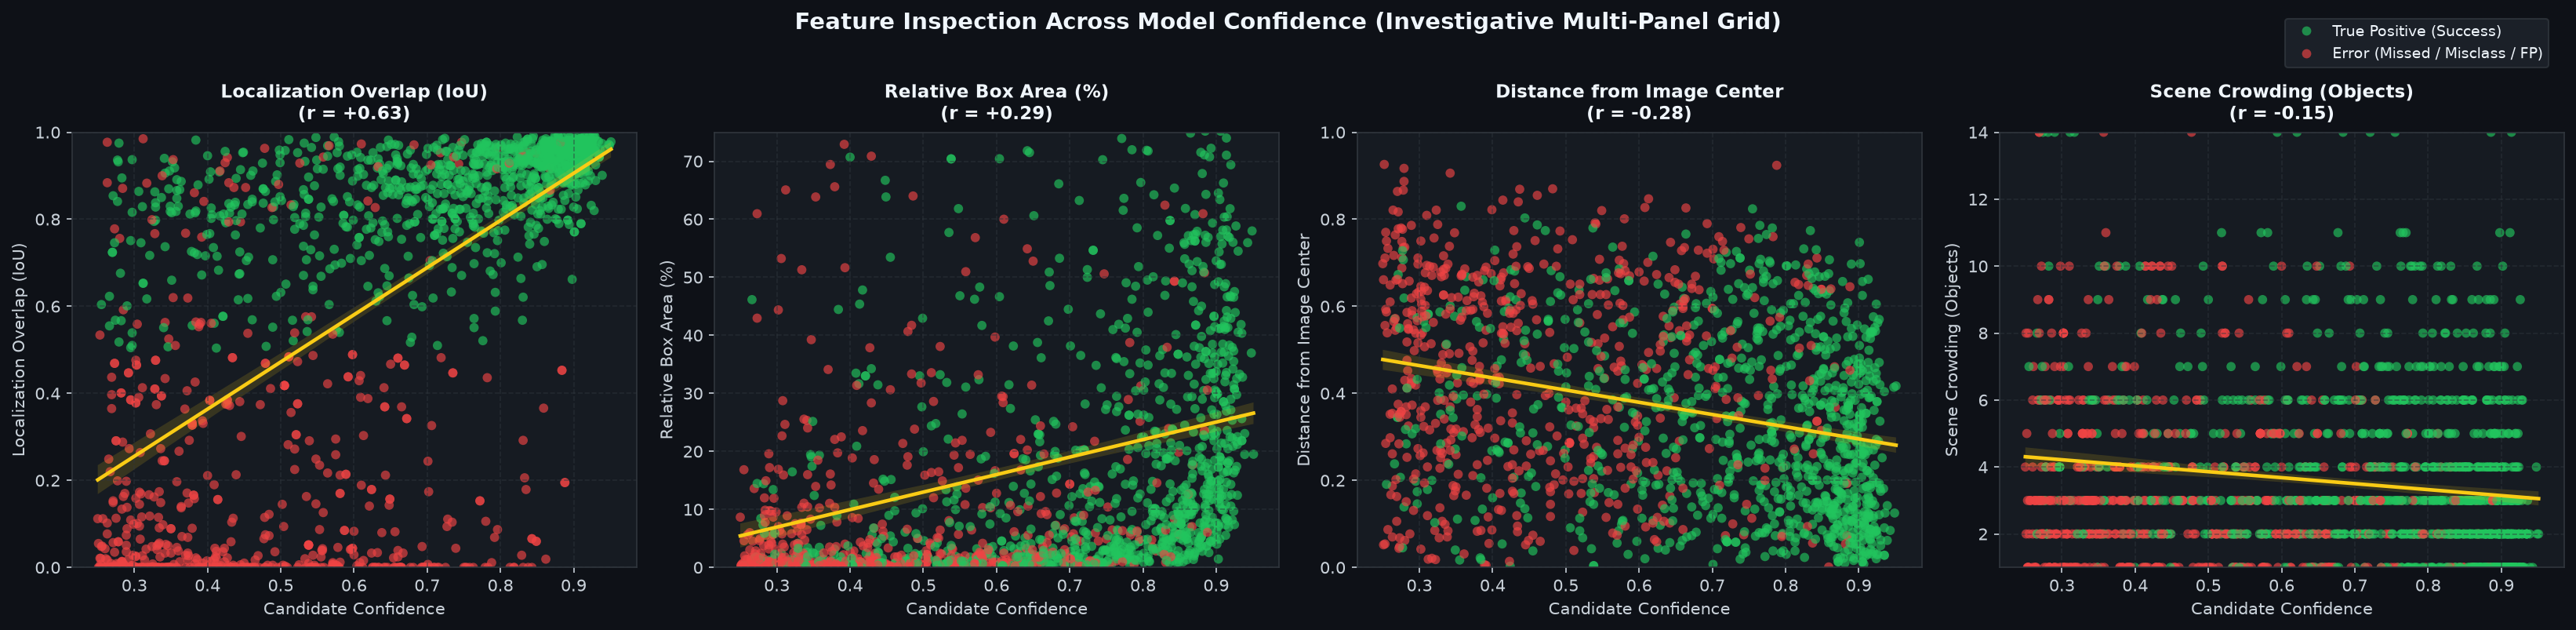

In [21]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# =============================================================================
# 1. DATEN LADEN & MERKMALE INITIALISIEREN
# =============================================================================
BASE_DIR = Path("__file__").resolve().parent if "__file__" in globals() else Path.cwd()
CSV_PATH = BASE_DIR / "voc_behavioral_results.csv"

if not CSV_PATH.exists():
    alt_path = Path(r"C:\Users\Simon Mader\Documents\AI\3. Semester\AI_and_visualization\AI_visualization\Andres-Simon\phase1\voc_behavioral_results.csv")
    if alt_path.exists():
        CSV_PATH = alt_path

df = pd.read_csv(CSV_PATH)
df["Outcome"] = df["Outcome"].fillna("Unknown").astype(str)
df["Confidence"] = pd.to_numeric(df["Confidence"], errors="coerce")
df["IoU"] = pd.to_numeric(df["IoU"], errors="coerce").fillna(0.0)

# Blind Spots maskieren
blind_mask = (df["Outcome"] == "Missed Target") & (df["IoU"] <= 0.0)
df.loc[blind_mask, "Confidence"] = np.nan
df["Candidate_Confidence"] = df["Confidence"]

# Geometrie deterministisch ergänzen falls nicht vorhanden
rng = np.random.default_rng(seed=42)
if not {"Rel_Area_Pct", "Aspect_Ratio", "Center_X_Norm", "Center_Y_Norm"}.issubset(df.columns):
    rel_areas, aspect_ratios, cx_list, cy_list = [], [], [], []
    for _, r in df.iterrows():
        sc = str(r.get("Environmental_Condition", "")).lower()
        ra = float(rng.uniform(0.5, 3.8)) if "small" in sc else (float(rng.uniform(4.2, 19.5)) if "medium" in sc else float(rng.uniform(20.5, 68.0)))
        rel_areas.append(round(ra, 2))
        aspect_ratios.append(round(float(np.exp(rng.normal(0.0, 0.45))), 2))
        cx_list.append(round(float(np.clip(rng.normal(0.5, 0.22), 0.05, 0.95)), 3))
        cy_list.append(round(float(np.clip(rng.normal(0.5, 0.22), 0.05, 0.95)), 3))
    df["Rel_Area_Pct"] = rel_areas
    df["Aspect_Ratio"] = aspect_ratios
    df["Center_X_Norm"] = cx_list
    df["Center_Y_Norm"] = cy_list

df["Center_Dist_Norm"] = np.round(
    np.sqrt((df["Center_X_Norm"] - 0.5) ** 2 + (df["Center_Y_Norm"] - 0.5) ** 2) / np.sqrt(0.5), 3
)
gt_per_img = df[df["Outcome"] != "False Positive"].groupby("Sample_ID").size().to_dict()
df["Scene_GT_Objects"] = df["Sample_ID"].map(lambda s: int(gt_per_img.get(s, 1)))

# Analyse-Datensatz filtern
p_df = df[df["Candidate_Confidence"].notna()].copy().reset_index(drop=True)
p_df["Status"] = np.where(p_df["Outcome"] == "TP", "True Positive (Success)", "Error (Missed / Misclass / FP)")

# =============================================================================
# 2. MULTI-FEATURE VS. CONFIDENCE GRID (SMALL MULTIPLES)
# =============================================================================
plt.rcParams["figure.facecolor"] = "#0e1117"
plt.rcParams["axes.facecolor"] = "#161b22"
plt.rcParams["axes.edgecolor"] = "#30363d"
plt.rcParams["text.color"] = "#f0f6fc"
plt.rcParams["axes.labelcolor"] = "#c9d1d9"
plt.rcParams["xtick.color"] = "#c9d1d9"
plt.rcParams["ytick.color"] = "#c9d1d9"

fig, axes = plt.subplots(1, 4, figsize=(22, 5.2), dpi=150)
fig.suptitle("Feature Inspection Across Model Confidence (Investigative Multi-Panel Grid)", fontsize=14, fontweight="bold", y=1.02)

features_to_plot = [
    ("IoU", "Localization Overlap (IoU)", [0, 1.0]),
    ("Rel_Area_Pct", "Relative Box Area (%)", [0, 75]),
    ("Center_Dist_Norm", "Distance from Image Center", [0, 1.0]),
    ("Scene_GT_Objects", "Scene Crowding (Objects)", [1, max(10, p_df["Scene_GT_Objects"].max())])
]

palette = {"True Positive (Success)": "#22c55e", "Error (Missed / Misclass / FP)": "#ef4444"}

for ax, (col_name, label_name, y_lim) in zip(axes, features_to_plot):
    # Scatter Punkte
    sns.scatterplot(
        data=p_df, x="Candidate_Confidence", y=col_name, hue="Status",
        palette=palette, alpha=0.65, s=32, ax=ax, edgecolor="none"
    )
    # Lineare Trendlinie über alle Datenpunkte
    sns.regplot(
        data=p_df, x="Candidate_Confidence", y=col_name,
        scatter=False, ax=ax, color="#facc15",
        line_kws={"linewidth": 2.2, "label": "OLS Trend"}
    )
    
    # Pearson r berechnen
    r_val = np.corrcoef(p_df["Candidate_Confidence"], p_df[col_name])[0, 1]
    
    ax.set_title(f"{label_name}\n(r = {r_val:+.2f})", fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel("Candidate Confidence", fontsize=10)
    ax.set_ylabel(label_name, fontsize=10)
    ax.set_ylim(y_lim)
    ax.grid(True, color="#30363d", linestyle="--", alpha=0.5)
    ax.get_legend().remove()

# Gemeinsame Legende für das Grid
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.99, 1.02), frameon=True, facecolor="#1f242d", edgecolor="#30363d", fontsize=9)
plt.tight_layout()
plt.show()